In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

Path("../results").mkdir(exist_ok=True)

X = pd.read_csv("../data/features_nested.csv")      # cambio 1: features del nested sampling (12)
CLASES = ["SLSN-I", "SN II", "SN IIn", "SN Ia", "SN Ib/c"]
FEATS = [c for c in X.columns if c not in ("NAME", "CLASE")]
y = X["CLASE"].map({c: i for i, c in enumerate(CLASES)}).to_numpy()
Xf = X[FEATS].to_numpy()

print(Xf.shape, np.bincount(y))

(4902, 12) [  69  763  187 3694  189]


In [2]:
def corre_cv(seed, metodo):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
    pred_s = np.empty(len(y), dtype=int)
    for tr, te in skf.split(Xf, y):
        Xtr, ytr, Xte = Xf[tr], y[tr], Xf[te]
        cw = None
        if metodo == "pesos":
            cw = "balanced"
        elif metodo == "smote":
            Xtr, ytr = SMOTE(random_state=seed, k_neighbors=5).fit_resample(Xtr, ytr)
        elif metodo == "smote_esc":                      # SMOTE con features estandarizadas
            sc = StandardScaler().fit(Xtr)
            Xtr, ytr = SMOTE(random_state=seed, k_neighbors=5).fit_resample(sc.transform(Xtr), ytr)
            Xte = sc.transform(Xte)
        m = lgb.LGBMClassifier(boosting_type="dart", n_estimators=250, max_depth=5,
                               num_leaves=20, reg_lambda=5, class_weight=cw,
                               random_state=seed, verbose=-1).fit(Xtr, ytr)
        pred_s[te] = m.predict(Xte)
    return pred_s

In [3]:
N_SEMILLAS = 5
filas = []
for metodo in ["ninguno", "pesos", "smote", "smote_esc"]:
    for s in range(N_SEMILLAS):
        p = corre_cv(s, metodo)
        cm_s = confusion_matrix(y, p)
        filas.append({"metodo": metodo, "semilla": s,
                      "accuracy": accuracy_score(y, p),
                      "F1_macro": f1_score(y, p, average="macro"),
                      **{f"comp_{c}": v for c, v in zip(CLASES, cm_s.diagonal() / cm_s.sum(axis=1))},
                      **{f"pur_{c}": v for c, v in zip(CLASES, cm_s.diagonal() / cm_s.sum(axis=0))}})
        print(metodo, s, flush=True)

res_bal = pd.DataFrame(filas)
res_bal.to_csv("../results/comparacion_balanceo_nested.csv", index=False)     # cambio 2: otro archivo de salida
cols = ["accuracy", "F1_macro", "comp_SLSN-I", "comp_SN Ib/c", "pur_SLSN-I", "pur_SN Ib/c"]
print(res_bal.groupby("metodo")[cols].agg(["mean", "std"]).round(3))

ninguno 0
ninguno 1
ninguno 2
ninguno 3
ninguno 4
pesos 0
pesos 1
pesos 2
pesos 3
pesos 4
smote 0
smote 1
smote 2
smote 3
smote 4
smote_esc 0
smote_esc 1
smote_esc 2
smote_esc 3
smote_esc 4
          accuracy        F1_macro        comp_SLSN-I        comp_SN Ib/c  \
              mean    std     mean    std        mean    std         mean   
metodo                                                                      
ninguno      0.889  0.001    0.591  0.010       0.287  0.021        0.247   
pesos        0.856  0.005    0.618  0.005       0.481  0.033        0.643   
smote        0.849  0.005    0.601  0.008       0.522  0.031        0.672   
smote_esc    0.845  0.005    0.593  0.009       0.493  0.018        0.662   

                 pur_SLSN-I        pur_SN Ib/c         
             std       mean    std        mean    std  
metodo                                                 
ninguno    0.031      0.569  0.028       0.519  0.028  
pesos      0.015      0.387  0.021       0.326

Balancear sigue siendo necesario. Sin balancear, las clases raras casi no se detectan. Con pesos sube a 0,48 y 0,64, a costa de pureza.
El costo en pureza es menor con mejores features. Antes la pureza de SLSN-I caía de 0,45 a 0,20 al balancear, y ahora cae de 0,57 a 0,39. En Ib/c pasa de 0,57 a 0,26 antes y de 0,52 a 0,33 ahora.
SMOTE ya no aporta mucho. Con curve_fit, SMOTE subía la completitud de SLSN-I de 0,28 a 0,43 y el F1 quedaba igual. Ahora la subida es de 0,48 a 0,52, dentro de la variación entre semillas. Además baja la pureza de SLSN-I y el F1 macro es algo menor que con pesos. Con features buenas, los pesos de clase bastan.
Mejores features ayudan en todos los métodos. El F1 sube 0,05 a 0,08 en las cuatro filas, y es un efecto mayor que el de elegir un método de balanceo.

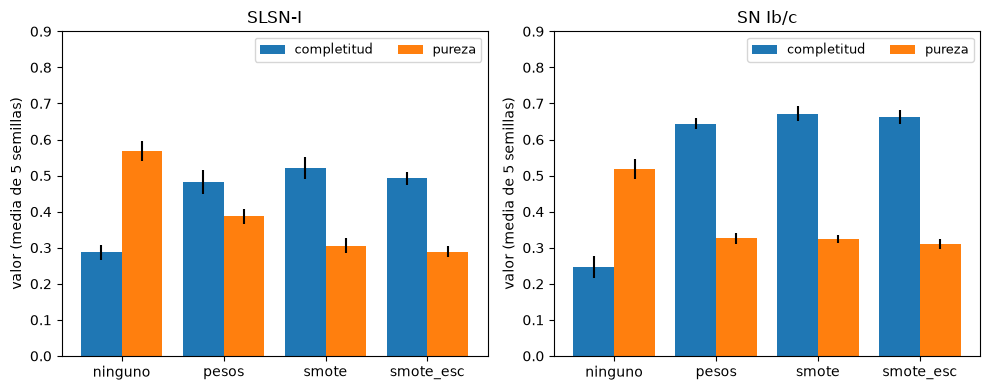

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
metodos = ["ninguno", "pesos", "smote", "smote_esc"]
g = res_bal.groupby("metodo")
for a, clase in zip(ax, ["SLSN-I", "SN Ib/c"]):
    cols_c = [f"comp_{clase}", f"pur_{clase}"]
    m, s = g[cols_c].mean().loc[metodos], g[cols_c].std().loc[metodos]
    x = np.arange(len(metodos))
    a.bar(x - 0.2, m[cols_c[0]], 0.4, yerr=s[cols_c[0]], label="completitud")
    a.bar(x + 0.2, m[cols_c[1]], 0.4, yerr=s[cols_c[1]], label="pureza")
    a.set_xticks(x); a.set_xticklabels(metodos)
    a.set_title(clase); a.set_ylabel("valor (media de 5 semillas)")
    a.set_ylim(0, 0.9)
    a.legend(loc="upper right", ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig("../results/balanceo_comp_pureza_nested.png", dpi=150)
plt.show()

In [5]:
ant = pd.read_csv("../results/comparacion_balanceo.csv")
cols = ["accuracy", "F1_macro", "comp_SLSN-I", "comp_SN Ib/c", "pur_SLSN-I", "pur_SN Ib/c"]
print("features de curve_fit:"); print(ant.groupby("metodo")[cols].mean().round(3))
print("features del nested sampling:"); print(res_bal.groupby("metodo")[cols].mean().round(3))

features de curve_fit:
           accuracy  F1_macro  comp_SLSN-I  comp_SN Ib/c  pur_SLSN-I  \
metodo                                                                 
ninguno       0.876     0.522        0.154         0.141       0.447   
pesos         0.828     0.540        0.284         0.531       0.200   
smote         0.816     0.541        0.426         0.544       0.210   
smote_esc     0.820     0.545        0.380         0.564       0.223   

           pur_SN Ib/c  
metodo                  
ninguno          0.574  
pesos            0.263  
smote            0.240  
smote_esc        0.234  
features del nested sampling:
           accuracy  F1_macro  comp_SLSN-I  comp_SN Ib/c  pur_SLSN-I  \
metodo                                                                 
ninguno       0.889     0.591        0.287         0.247       0.569   
pesos         0.856     0.618        0.481         0.643       0.387   
smote         0.849     0.601        0.522         0.672       0.306   
smot

In [6]:
ant = pd.read_csv("../results/comparacion_balanceo.csv")
cols = ["accuracy", "F1_macro", "comp_SLSN-I", "comp_SN Ib/c", "pur_SLSN-I", "pur_SN Ib/c"]
print("features de curve_fit:"); print(ant.groupby("metodo")[cols].mean().round(3))
print("features del nested sampling:"); print(res_bal.groupby("metodo")[cols].mean().round(3))

features de curve_fit:
           accuracy  F1_macro  comp_SLSN-I  comp_SN Ib/c  pur_SLSN-I  \
metodo                                                                 
ninguno       0.876     0.522        0.154         0.141       0.447   
pesos         0.828     0.540        0.284         0.531       0.200   
smote         0.816     0.541        0.426         0.544       0.210   
smote_esc     0.820     0.545        0.380         0.564       0.223   

           pur_SN Ib/c  
metodo                  
ninguno          0.574  
pesos            0.263  
smote            0.240  
smote_esc        0.234  
features del nested sampling:
           accuracy  F1_macro  comp_SLSN-I  comp_SN Ib/c  pur_SLSN-I  \
metodo                                                                 
ninguno       0.889     0.591        0.287         0.247       0.569   
pesos         0.856     0.618        0.481         0.643       0.387   
smote         0.849     0.601        0.522         0.672       0.306   
smot